# SPSA for Layer-Wise Training of Neural Networks

**Research implementation and learning notebook**

**Research basis:** Wulff, Schuecker and Bauckhage, *SPSA for Layer-Wise Training of Deep Networks* (ICANN 2018).

## Project objective

This project studies training a small neural network using **Simultaneous Perturbation Stochastic Approximation (SPSA)**. SPSA estimates a gradient from two loss evaluations using simultaneous random perturbations, rather than calculating parameter gradients through backpropagation.

The separate [optimizer comparison notebook](02_Optimizer_Comparison.ipynb) compares SPSA with SGD and Adam on Moons.

### What this notebook covers

1. Neural-network structure and forward propagation
2. Squared-error loss
3. SPSA gradient estimation
4. Holistic and layer-wise parameter updates
5. MNIST data preparation and SPSA training
6. Evaluation, predictions and checkpointing
7. Summary of the current experiments

## 1. Environment and imports

Run this notebook using the project's virtual environment. Install the dependencies listed in `requirements.txt` before running the notebook.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split


## 2. Neural-network fundamentals

Our MNIST network has three layers of widths **784 → 196 → 10**:

- 784 input values: one for each pixel in a 28 × 28 image
- 196 hidden units
- 10 output units: one score for each digit from 0 to 9

Each layer has weights and biases. We apply the hyperbolic tangent (`tanh`) activation after each affine transformation.

The output values are **scores**, not calibrated probabilities. For classification, we select the index of the largest output score.

The implementation is in [neural_network.py](neural_network.py). Read its methods in this order: `__init__` defines parameter slices, `initialize` creates weights and biases, `forward` calculates scores, and `predict` selects a class.


In [2]:
from neural_network import DenseTanhNetwork

# Create the network; weights and biases are initialized when training starts.
network = DenseTanhNetwork([784, 196, 10], slope=1.0)
print("Number of trainable parameters:", network.n_parameters)

Number of trainable parameters: 155830


## 3. Target encoding and loss function

For ten-class classification, each label is represented as a one-hot vector. For example, digit 3 is represented by a vector whose fourth element is 1 and all other elements are 0.

The network uses `tanh`, whose output range is [-1, 1]. We therefore map target values from {0, 1} to {-1, 1}.

The loss used in this implementation is the mean, across examples, of the sum of squared output residuals.

In [3]:
from neural_network import encode_targets, mean_squared_error

## 4. SPSA: the optimization method

SPSA estimates all coordinates of the gradient using only two objective function evaluations per iteration, regardless of the number of parameters.

At each iteration, a random perturbation vector is generated, with each element taking a value of $-1$ or $+1$. The gradient is estimated using the difference between the loss values at positively and negatively perturbed parameter vectors:

$$
\hat{g}_i(\theta) = \frac{L(\theta + c_t \Delta) - L(\theta - c_t \Delta)}{2 c_t \Delta_i}
$$

The parameters are updated in the direction opposite to the estimated gradient:

$$
\theta_{t+1} = \theta_t - a_t \hat{g}(\theta_t)
$$

The learning rate and perturbation magnitude decrease over iterations according to:

$$
a_t = \frac{a}{t^\alpha}, \qquad c_t = \frac{c}{t^\gamma}
$$

Unlike backpropagation, SPSA estimates the gradient from two loss evaluations without explicitly calculating derivatives.

In [4]:
from spsa_optimizer import spsa_minimize

## 4A. Watch SPSA minimize a mathematical function

For $f(x)=x_1^2+x_2^2$, the known minimum is zero at (0, 0). This example
isolates optimization from the neural network. Monitoring uses one extra loss
evaluation per recorded point; each SPSA update itself still uses exactly two.
The illustrative settings here differ from the MNIST configuration.

Final point: [ 0.00116726 -0.00106741]
Initial and final loss: 13.0 2.501863861821211e-06


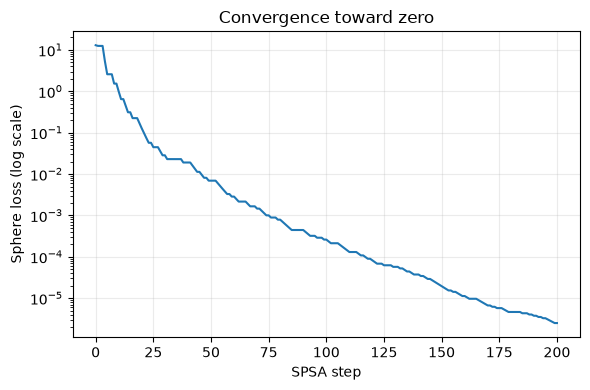

In [5]:
def sphere(parameters):
    return float(np.sum(parameters ** 2))

minimum, sphere_history = spsa_minimize(
    sphere, [3.0, -2.0], np.random.default_rng(4), steps=200,
    learning_rate=0.2, perturbation=0.1, alpha=0.602, return_history=True,
)
print('Final point:', minimum)
print('Initial and final loss:', sphere_history['loss'][0], sphere_history['loss'][-1])
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(sphere_history['loss'])
ax.set(xlabel='SPSA step', ylabel='Sphere loss (log scale)', title='Convergence toward zero')
ax.grid(alpha=0.25)
fig.tight_layout()
Path('outputs/figures').mkdir(parents=True, exist_ok=True)
fig.savefig('outputs/figures/sphere_convergence.png', dpi=160)
plt.show()

## 5. Layer-wise parameter blocks

A **holistic** update optimizes the complete parameter vector. A **layer-wise** update optimizes one layer's parameters while holding the other layers fixed.

The available layer orders are:

- `bottom_up`: input layer toward output layer
- `top_down`: output layer toward input layer
- `random`: shuffle the layer order for each block sequence
- `holistic`: optimize all parameters as one block

For the MNIST experiment, we can further split each layer into its weight block and bias block.

In [6]:
from training import get_parameter_blocks

## 6. SPSA training loop

For each minibatch and each selected parameter block:

1. Keep a copy of the current complete parameter vector.
2. Perturb only the active block in the positive and negative directions.
3. Evaluate the loss for both perturbed candidates on the same minibatch.
4. Update the active block using the SPSA estimate.
5. Leave all other blocks unchanged.

The MNIST learning-rate coefficient is `0.001`. The Moons demonstration uses its own settings.

The implementation is in [training.py](training.py). Histories include epoch zero. The decay schedule restarts for each block, preserving the original update rule. Pass `shuffle_seed` to separate minibatch shuffling from SPSA perturbations when comparing optimizers.

In [7]:
from training import train_spsa, prepare_moons_data

## 6A. Run a small classification experiment

Two interlocking moons provide a nonlinear two-class problem without downloading data.
We use a **2 → 8 → 2** tanh network. Labels are encoded as [-1, +1] or [+1, -1].
Only the training split determines feature scaling. Validation data is monitored; the test
set is used after training. These results belong to the Moons experiment and are separate from the MNIST run below.

Read the modules in this order: [neural_network.py](neural_network.py),
[spsa_optimizer.py](spsa_optimizer.py), [training.py](training.py), [evaluation.py](evaluation.py).

Initial loss: 3.3055
Final loss: 0.6979
SPSA objective evaluations: 9600


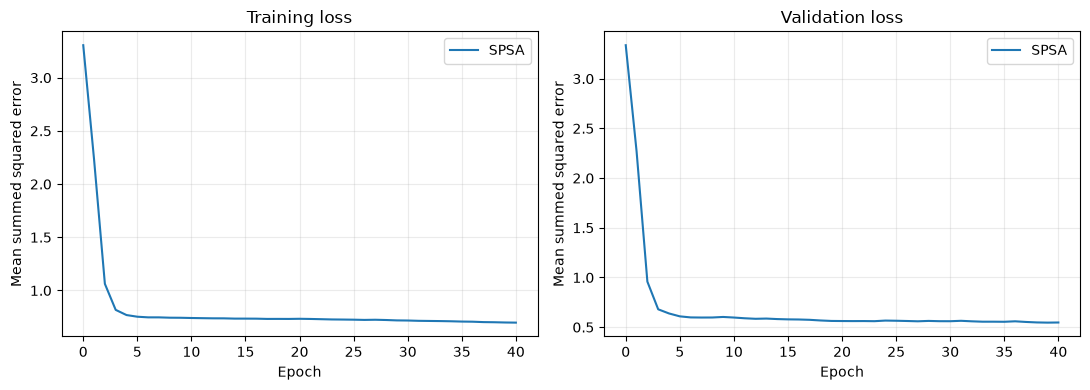

In [8]:
from evaluation import plot_loss_curves, save_checkpoint, predict_checkpoint

data = prepare_moons_data(seed=42)
demo_network = DenseTanhNetwork([2, 8, 2])
initial_parameters = demo_network.initialize(seed=0)
demo_parameters, demo_history = train_spsa(
    demo_network, initial_parameters, data['X_train'], data['Y_train'],
    epochs=40, batch_size=64, inner_steps=5, learning_rate=0.03,
    perturbation=0.1, order='bottom_up', split_weights_biases=True,
    seed=1000, shuffle_seed=2000,
    validation_data=(data['X_validation'], data['Y_validation']), verbose=False,
)
print(f"Initial loss: {demo_history['training_loss'][0]:.4f}")
print(f"Final loss: {demo_history['training_loss'][-1]:.4f}")
print('SPSA objective evaluations:', demo_history['objective_evaluations'][-1])
plot_loss_curves({'SPSA': demo_history}, 'outputs/figures/spsa_moons_loss.png')
plt.show()

Accuracy: 88.333%
              precision    recall  f1-score   support

           0       0.88      0.88      0.88        60
           1       0.88      0.88      0.88        60

    accuracy                           0.88       120
   macro avg       0.88      0.88      0.88       120
weighted avg       0.88      0.88      0.88       120



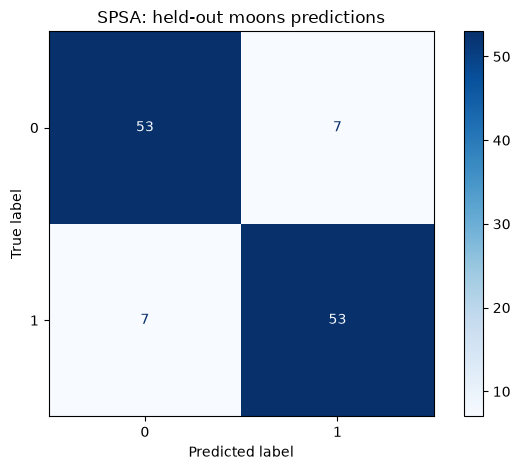

Checkpoint reload reproduces the predictions.


In [9]:
from evaluation import evaluate_classifier

predictions = evaluate_classifier(
    demo_network, demo_parameters, data['X_test'], data['y_test'],
    title='SPSA: held-out moons predictions',
)
checkpoint_path = 'outputs/checkpoints/spsa_moons_demo.npz'
save_checkpoint(checkpoint_path, demo_network, demo_parameters,
                {'dataset': 'moons', 'data_seed': 42, 'initialization_seed': 0,
                 'perturbation_seed': 1000, 'shuffle_seed': 2000,
                 'epochs': 40, 'batch_size': 64, 'inner_steps': 5,
                 'learning_rate': 0.03, 'perturbation': 0.1,
                 'order': 'bottom_up', 'split_weights_biases': True},
                mean=data['mean'], scale=data['scale'])
raw_test = data['X_test'] * data['scale'] + data['mean']
np.testing.assert_array_equal(predict_checkpoint(checkpoint_path, raw_test), predictions)
print('Checkpoint reload reproduces the predictions.')

## 7. Load and prepare MNIST

Load the cached MNIST images, flatten each 28 x 28 image to 784 inputs, and scale pixel values from [0, 255] to [0, 1].

This experiment creates a stratified split of 1,600 training, 400 validation, and 1,000 test images using split seeds 42 and 43. It is separate from the Moons experiment.

In [12]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from neural_network import encode_targets

with np.load("data/mnist.npz", allow_pickle=False) as saved:
    images = np.concatenate([saved["x_train"], saved["x_test"]])
    labels = np.concatenate([saved["y_train"], saved["y_test"]])

X_all = images.reshape(-1, 784).astype(np.float64) / 255.0
y_all = labels.astype(np.int64)

X_pool, X_test, y_pool, y_test = train_test_split(
    X_all, y_all,
    train_size=2000,
    test_size=1000,
    random_state=42,
    stratify=y_all,
)

X_train, X_validation, y_train, y_validation = train_test_split(
    X_pool, y_pool,
    test_size=400,
    random_state=43,
    stratify=y_pool,
)

Y_train = encode_targets(y_train)
Y_validation = encode_targets(y_validation)

print("Training:", X_train.shape, Y_train.shape)
print("Validation:", X_validation.shape, Y_validation.shape)
print("Test:", X_test.shape, y_test.shape)
print("Pixel range:", X_train.min(), X_train.max())
print("Target values:", np.unique(Y_train))

Training: (1600, 784) (1600, 10)
Validation: (400, 784) (400, 10)
Test: (1000, 784) (1000,)
Pixel range: 0.0 1.0
Target values: [-1.  1.]


## 8. Run the SPSA MNIST experiment

Train the 784 -> 196 -> 10 network for 12 epochs using bottom-up SPSA with separate weight and bias blocks. Each epoch prints its training loss; validation loss is recorded without updating parameters from validation data.

This cell starts a new training run and may take several minutes.

In [13]:
from neural_network import DenseTanhNetwork
from training import train_spsa

network = DenseTanhNetwork([784, 196, 10], slope=1.0)
initial_parameters = network.initialize(seed=0)

spsa_parameters, spsa_history = train_spsa(
    network,
    initial_parameters,
    X_train,
    Y_train,
    epochs=12,
    batch_size=128,
    inner_steps=50,
    learning_rate=0.001,
    perturbation=0.1,
    order="bottom_up",
    split_weights_biases=True,
    seed=1000,
    shuffle_seed=2000,
    validation_data=(X_validation, Y_validation),
    verbose=True,
)

print("Initial training loss:", spsa_history["training_loss"][0])
print("Final training loss:", spsa_history["training_loss"][-1])
print("Final validation loss:", spsa_history["validation_loss"][-1])
print("SPSA objective evaluations:", spsa_history["objective_evaluations"][-1])

Epoch 01/12 - loss: 3.6874
Epoch 02/12 - loss: 3.5502
Epoch 03/12 - loss: 3.4885
Epoch 04/12 - loss: 3.3506
Epoch 05/12 - loss: 3.2200
Epoch 06/12 - loss: 3.1407
Epoch 07/12 - loss: 3.0450
Epoch 08/12 - loss: 2.9202
Epoch 09/12 - loss: 2.8541
Epoch 10/12 - loss: 2.7682
Epoch 11/12 - loss: 2.7094
Epoch 12/12 - loss: 2.6251
Initial training loss: 13.511337577738388
Final training loss: 2.625097596870154
Final validation loss: 2.7243851893810533
SPSA objective evaluations: 62400


## 9. Evaluate the trained model

Use validation data for model-development decisions. Keep the test set for final evaluation.

The following helper reports classification accuracy and displays a confusion matrix.

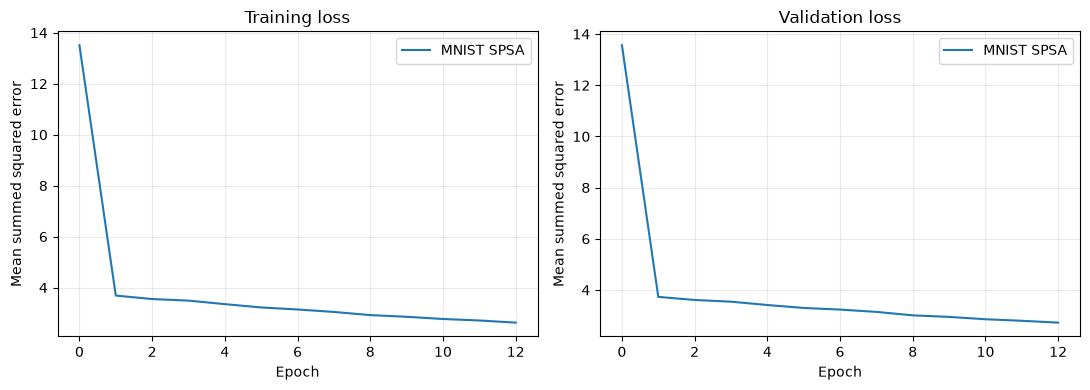

Accuracy: 51.900%
              precision    recall  f1-score   support

           0       0.64      0.87      0.74        99
           1       0.68      0.96      0.79       113
           2       0.47      0.51      0.49       100
           3       0.54      0.54      0.54       102
           4       0.50      0.10      0.17        97
           5       0.46      0.12      0.19        90
           6       0.44      0.90      0.59        98
           7       0.41      0.83      0.55       104
           8       0.71      0.15      0.25        98
           9       0.38      0.09      0.15        99

    accuracy                           0.52      1000
   macro avg       0.52      0.51      0.45      1000
weighted avg       0.53      0.52      0.46      1000



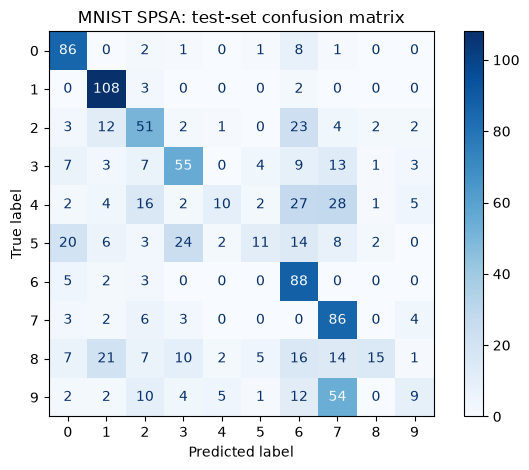

In [14]:
import matplotlib.pyplot as plt
from evaluation import plot_loss_curves, evaluate_classifier

plot_loss_curves(
    {"MNIST SPSA": spsa_history},
    "outputs/figures/mnist_spsa_current_run.png",
)
plt.show()

mnist_predictions = evaluate_classifier(
    network,
    spsa_parameters,
    X_test,
    y_test,
    title="MNIST SPSA: test-set confusion matrix",
)

## 10. Save and reload a checkpoint

A checkpoint should contain the parameter vector and enough architecture information to reconstruct the network. Save the experiment configuration alongside it so that the result can be interpreted later.

In [15]:
import numpy as np
from evaluation import save_checkpoint, predict_checkpoint, save_experiment

checkpoint_path = "outputs/checkpoints/mnist_spsa_current_run.npz"

metadata = {
    "dataset": "MNIST",
    "optimizer": "SPSA",
    "train_size": 1600,
    "validation_size": 400,
    "test_size": 1000,
    "initialization_seed": 0,
    "perturbation_seed": 1000,
    "shuffle_seed": 2000,
    "split_seeds": [42, 43],
    "epochs": 12,
    "batch_size": 128,
    "inner_steps": 50,
    "learning_rate": 0.001,
    "perturbation": 0.1,
    "alpha": 1.0,
    "gamma": 1 / 6,
    "order": "bottom_up",
    "split_weights_biases": True,
    "test_accuracy": float(np.mean(mnist_predictions == y_test)),
}

save_checkpoint(
    checkpoint_path,
    network,
    spsa_parameters,
    metadata,
    mean=np.zeros(784),
    scale=np.full(784, 255.0),
)

# The checkpoint expects raw pixel values, before division by 255.
raw_test_images = X_test * 255.0
reloaded_predictions = predict_checkpoint(checkpoint_path, raw_test_images)

np.testing.assert_array_equal(reloaded_predictions, mnist_predictions)

save_experiment(
    "outputs/experiments/mnist_spsa_current_run.json",
    {"configuration": metadata, "history": spsa_history},
)

print("MNIST checkpoint saved.")
print("Reloaded predictions match exactly.")
print("Experiment settings and loss history saved.")

MNIST checkpoint saved.
Reloaded predictions match exactly.
Experiment settings and loss history saved.


## 11. Conclusion

SPSA minimized the sphere function and trained neural networks using forward-only loss evaluations.

The current MNIST run reduced training loss from 13.5113 to 2.6251, with final validation loss 2.7244 and test accuracy 51.9% on 1,000 images. It used 62,400 SPSA objective evaluations. Reloading its checkpoint reproduced identical predictions.

The separate [optimizer comparison notebook](02_Optimizer_Comparison.ipynb) compares SPSA, SGD, and Adam on Moons. Its results apply to that dataset and configuration; this MNIST run evaluates SPSA only.

### Limitations

- The current MNIST experiment uses a small subset and one training seed.
- The Moons comparison uses three training seeds and equal epochs, not equal compute.
- Optimizer settings were not exhaustively tuned.
- These experiments demonstrate the methods; they are not exact reproductions of the paper.

## References

1. Wulff, B., Schuecker, J. and Bauckhage, C. (2018). *SPSA for Layer-Wise Training of Deep Networks*. ICANN 2018. https://doi.org/10.1007/978-3-030-01424-7_55
2. SimpleArt SPSA repository, pinned commit used in the original experiments: https://github.com/SimpleArt/spsa/tree/55ff58868f9b5e515dff4b55c8d0671f0f124f3d